# Chicago crime data analysis

This notebook follows the data from the six supplied CSVs to the numbers and charts used by the Flask app. It covers inspection and cleaning, exploratory analysis, statistical checks, and database reporting.

Select the project's `.venv\Scripts\python.exe` kernel in VS Code and choose **Run All**. The six source CSVs are in the project's `data` folder. The SQL section builds a temporary SQLite database from those files. The Flask app stores edits in its own working database.

In [1]:
import calendar
from pathlib import Path
from tempfile import TemporaryDirectory

from IPython.display import display

from database import ROOT, create_read_engine
from use_case_1 import DATASET_DIR, FILES, clean_crimes, prepare_dimensions, read_source, run_pipeline

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import text

sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": "#f6f1e6",
    "axes.facecolor": "#fffdf7",
    "axes.labelcolor": "#173833",
    "text.color": "#173833",
})
green, rust = "#397665", "#a33524"

print(f"Source folder: {DATASET_DIR.name}")
print(f"Project: {ROOT.name}")

Source folder: data
Project: chicago-crime-explorer


## Use Case 1 · Inspect and clean the data

### 1. Load the source files

The crime CSV supplies incidents. The other five files describe community areas, police districts, offence codes, police beats, and ward offices. Source columns initially use strings so codes can keep leading zeroes. `read_source()` uses a strict parser for the incident file and records any repairs or unreadable rows.

In [2]:
repairs, rejected = [], []
sources = {
    table: read_source(DATASET_DIR / filename, repairs, rejected)
    for table, filename in FILES.items()
}
parser_rejections = len(rejected)
raw = sources["chicago_crime"]
raw_columns = raw.drop(columns="source_row")

display(pd.DataFrame([
    {"source_file": filename, "parsed_rows": len(sources[table]),
     "source_columns": sources[table].shape[1] - 1}
    for table, filename in FILES.items()
]))
print("Crime CSV shape (rows, source columns):", raw_columns.shape)
display(raw_columns.head(10))
display(raw_columns.dtypes.rename("source_dtype").to_frame())
display(pd.DataFrame(repairs))

,source_file,parsed_rows,source_columns
0,chicago_city_community.csv,77,7
1,chicago_district_ps_info.csv,22,15
2,iucr_codes.csv.csv,410,4
3,chicago_police_beat_info.csv,277,4
4,chicago_ward_offices.csv,58,20
5,chicago_crime_dataset.csv,498,20


Crime CSV shape (rows, source columns): (498, 20)


,id,case_number,date,block,iucr_code,location_desc,arrest,domestic,beat_num,district_code,ward_no,community_code,fbi_code,x_coordinate,y_coordinate,year,date_of_update,latitude,longitude,location
0,10508693,HZ250496,5/3/2016,013XX S SAWYER AVE,486,APARTMENT,TRUE,TRUE,1022,10,24,29,08B,1154907,1893681,2016,5/10/2016,41.86407316,-87.70681861,"(41.864073157, -87.706818608)"
1,10508695,HZ250409,5/3/2016,061XX S DREXEL AVE,486,RESIDENCE,FALSE,TRUE,313,3,20,42,08B,1183066,1864330,2016,5/10/2016,41.78292153,-87.60436317,"(41.782921527, -87.60436317)"
2,10508697,HZ250503,5/3/2016,053XX W CHICAGO AVE,470,STREET,FALSE,FALSE,1524,15,37,25,24,1140789,1904819,2016,5/10/2016,41.89490828,-87.75837196,"(41.894908283, -87.758371958)"
3,10508698,HZ250424,5/3/2016,049XX W FULTON ST,460,SIDEWALK,FALSE,FALSE,1532,15,28,25,08B,1143223,1901475,2016,5/10/2016,41.88568685,-87.74951598,"(41.885686845, -87.749515983)"
4,10508699,HZ250455,5/3/2016,003XX N LOTUS AVE,820,RESIDENCE,FALSE,TRUE,1523,15,28,25,6,1139890,1901675,2016,5/10/2016,41.88629724,-87.76175071,"(41.886297242, -87.761750709)"
5,10508702,HZ250447,5/3/2016,082XX S MARYLAND AVE,041A,STREET,FALSE,FALSE,631,6,8,44,04B,1183336,1850642,2016,5/10/2016,41.74535402,-87.6037989,"(41.745354023, -87.603798903)"
6,10508703,HZ250489,5/3/2016,027XX S STATE ST,460,CHA HALLWAY/STAIRWELL/ELEVATOR,FALSE,FALSE,133,1,3,35,08B,1176730,1886544,2016,5/10/2016,41.84402377,-87.62692325,"(41.844023772, -87.626923253)"
7,10508704,HZ250514,5/3/2016,002XX E 46TH ST,460,RESIDENCE PORCH/HALLWAY,FALSE,FALSE,215,2,3,38,08B,1178514,1874573,2016,5/10/2016,41.81113396,-87.62074077,"(41.811133958, -87.62074077)"
8,10508709,HZ250523,5/3/2016,014XX W DEVON AVE,460,SIDEWALK,FALSE,FALSE,2432,24,40,1,08B,1165696,1942616,2016,5/10/2016,41.99813061,-87.66581404,"(41.99813061, -87.665814038)"
9,10508982,HZ250667,5/3/2016,069XX S ASHLAND AVE,486,STREET,FALSE,TRUE,735,7,17,67,08B,1166876,1858796,2016,5/10/2016,41.76809684,-87.66387859,"(41.768096835, -87.663878589)"


,source_dtype
id,string
case_number,string
date,string
block,string
iucr_code,string
location_desc,string
arrest,string
domestic,string
beat_num,string
district_code,string


,source_row,action
0,498,Added missing closing quote to final coordinat...
1,499,Added missing closing quote to final coordinat...


The footprint above counts source fields only. The parser adds `source_row` for traceability. It repairs two missing closing quotes on the final coordinate field and keeps a record of both changes.

### 2. Check missing values before cleaning

`isna()` provides one boolean flag for each cell. NumPy averages the flags down each column to get the fraction that is missing.

In [3]:
missing = pd.DataFrame({
    "missing_rows": raw_columns.isna().sum(),
    "missing_pct": np.round(np.mean(raw_columns.isna().to_numpy(), axis=0) * 100, 2),
}).sort_values("missing_pct", ascending=False)
display(missing)
print("Columns above 50% missingness:", missing.index[missing["missing_pct"] > 50].tolist())

,missing_rows,missing_pct
location,29,5.82
y_coordinate,29,5.82
longitude,29,5.82
latitude,29,5.82
x_coordinate,29,5.82
location_desc,4,0.80
case_number,0,0.00
id,0,0.00
block,0,0.00
date,0,0.00


Columns above 50% missingness: []


### 3. Prepare lookup keys and clean the incidents

IUCR codes use four characters. Geographic keys use integers. We use unique ward keys for the relationship and keep the original ward-office rows separately. Repeated office records should not multiply incident counts when we join.

The shared `clean_crimes()` function converts types, normalises text, validates required fields with Pandera, and derives year, month, and weekday from the parsed date. It fills a missing location description with `UNKNOWN`. Missing coordinates stay missing. The audit records the decisions that affect row counts.

In [4]:
dimensions = prepare_dimensions(sources)
communities = dimensions["city_community"]

audit = {}
crimes = clean_crimes(raw, dimensions, audit, rejected)

display(pd.Series({
    "Accepted incidents": audit["accepted_records"],
    "Quarantined records": audit["quarantined_records"],
    "Invalid required fields": audit["invalid_key_records"],
    "Duplicate crime records": audit["duplicate_crime_records"],
    "Year mismatches": audit["year_mismatches"],
    "Out-of-range coordinates": audit["invalid_coordinates"],
    "Records missing latitude or longitude": audit["records_without_coordinates"],
    "Records with explicit incident time": audit["records_with_time"],
}, name="count").to_frame())
display(pd.Series(audit["unmatched_foreign_keys"], name="unmatched_codes").to_frame())

,count
Accepted incidents,498
Quarantined records,0
Invalid required fields,0
Duplicate crime records,0
Year mismatches,0
Out-of-range coordinates,0
Records missing latitude or longitude,29
Records with explicit incident time,0


,unmatched_codes
community_code,0
district_code,0
iucr_code,0
beat_num,0
ward_no,0


In [5]:
preview = crimes[["date", "year", "month", "day_of_week", "iucr_code", "location_desc", "arrest"]].copy()
preview["weekday"] = crimes["date"].dt.day_name()
display(preview.head(10))
display(preview.dtypes.rename("cleaned_dtype").to_frame())

assert len(crimes) + len(rejected) == len(raw) + parser_rejections
assert len(crimes) == audit["accepted_records"]
assert crimes["id"].is_unique and crimes["case_number"].is_unique

,date,year,month,day_of_week,iucr_code,location_desc,arrest,weekday
0,2016-05-03,2016,5,1,0486,APARTMENT,1,Tuesday
1,2016-05-03,2016,5,1,0486,RESIDENCE,0,Tuesday
2,2016-05-03,2016,5,1,0470,STREET,0,Tuesday
3,2016-05-03,2016,5,1,0460,SIDEWALK,0,Tuesday
4,2016-05-03,2016,5,1,0820,RESIDENCE,0,Tuesday
5,2016-05-03,2016,5,1,041A,STREET,0,Tuesday
6,2016-05-03,2016,5,1,0460,CHA HALLWAY/STAIRWELL/ELEVATOR,0,Tuesday
7,2016-05-03,2016,5,1,0460,RESIDENCE PORCH/HALLWAY,0,Tuesday
8,2016-05-03,2016,5,1,0460,SIDEWALK,0,Tuesday
9,2016-05-03,2016,5,1,0486,STREET,0,Tuesday


,cleaned_dtype
date,datetime64[us]
year,int32
month,int32
day_of_week,int32
iucr_code,string
location_desc,string
arrest,Int64
weekday,str


### 4. Join labels and verify cardinality

The incident file provides a code. The lookup files supply the labels. A many-to-one join means several incidents can refer to one lookup record. Comparing counts before and after joining catches accidental duplication.

In [6]:
offences = dimensions["iucr"][["iucr_code", "primary_type"]]
areas = communities[["community_code", "community_name", "population"]]

incidents = (
    crimes.merge(offences, on="iucr_code", how="left", validate="many_to_one")
    .merge(areas, on="community_code", how="left", validate="many_to_one")
)
incidents["primary_type"] = incidents["primary_type"].fillna("UNKNOWN")
assert len(incidents) == len(crimes)

print(f"{len(incidents)} incidents after both joins")
print(f"{incidents['primary_type'].nunique()} distinct primary offence categories")
print(f"{len(areas)} community areas in the reference file")

498 incidents after both joins
23 distinct primary offence categories
77 community areas in the reference file


## Use Case 2 · Explore the sample

### 1. Incidents and arrests by year

A recorded arrest is represented by 1. For the percentage, the denominator is the count of known arrest flags, including both Yes and No.

,year,incidents,arrests,known_flags,arrest_pct
0,2012,2,2,2,100.0
1,2013,1,1,1,100.0
2,2014,1,0,1,0.0
3,2015,4,2,4,50.0
4,2016,490,119,490,24.29


The two busiest dates account for 88.96% of the sample.


,incidents
date,
2016-05-04,298
2016-05-03,145


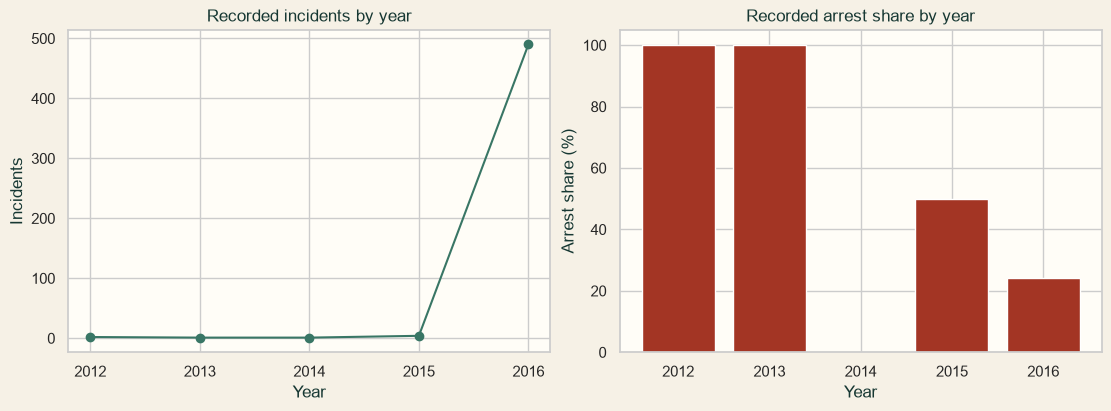

In [7]:
yearly = incidents.groupby("year", as_index=False).agg(
    incidents=("id", "size"),
    arrests=("arrest", "sum"),
    known_flags=("arrest", "count"),
)
yearly["arrest_pct"] = (100 * yearly["arrests"] / yearly["known_flags"].replace(0, np.nan)).round(2)
display(yearly)

daily = incidents["date"].dt.date.value_counts()
two_busiest_share = 100 * daily.head(2).sum() / len(incidents)
print(f"The two busiest dates account for {two_busiest_share:.2f}% of the sample.")
display(daily.head(2).rename("incidents").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(yearly["year"], yearly["incidents"], marker="o", color=green)
axes[0].set(title="Recorded incidents by year", xlabel="Year", ylabel="Incidents", xticks=yearly["year"])
axes[1].bar(yearly["year"], yearly["arrest_pct"], color=rust)
axes[1].set(title="Recorded arrest share by year", xlabel="Year", ylabel="Arrest share (%)",
            xticks=yearly["year"], ylim=(0, 105))
plt.show()

The 2016 count is much larger than the counts for earlier years, and the two busiest dates account for most observations. These totals describe file coverage. The small counts in early years make the annual arrest percentages unstable.

### 2. Offence distribution

The ranking uses the ten largest counts. Each share uses every selected incident as the denominator.

,primary_type,incidents,share_pct
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63
5,ASSAULT,35,7.03
6,NARCOTICS,32,6.43
7,ROBBERY,30,6.02
8,CRIMINAL TRESPASS,17,3.41
9,MOTOR VEHICLE THEFT,16,3.21


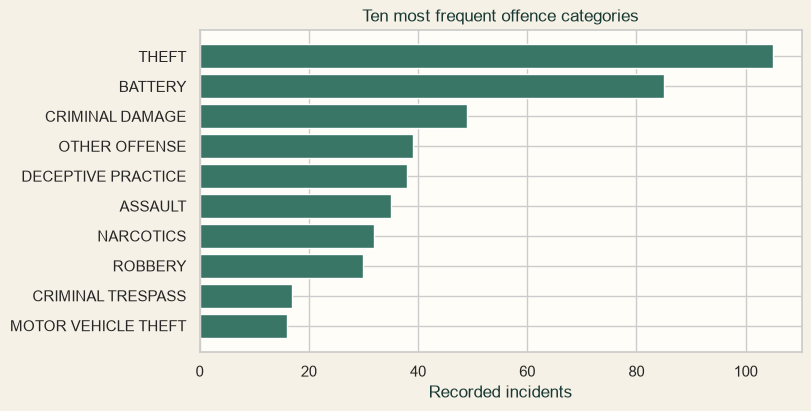

THEFT leads with 105 records (21.08%).


In [8]:
categories = (
    incidents["primary_type"].value_counts().rename("incidents").reset_index()
    .sort_values(["incidents", "primary_type"], ascending=[False, True])
)
categories["share_pct"] = (100 * categories["incidents"] / len(incidents)).round(2)
top = categories.head(10)
display(top.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.barh(top["primary_type"], top["incidents"], color=green)
ax.invert_yaxis()
ax.set(title="Ten most frequent offence categories", xlabel="Recorded incidents")
plt.show()

leader = top.iloc[0]
print(f"{leader['primary_type']} leads with {leader['incidents']} records ({leader['share_pct']:.2f}%).")

### 3. Month and weekday patterns

Each heatmap cell counts a month and weekday combination. A zero indicates no matching observation within the file.

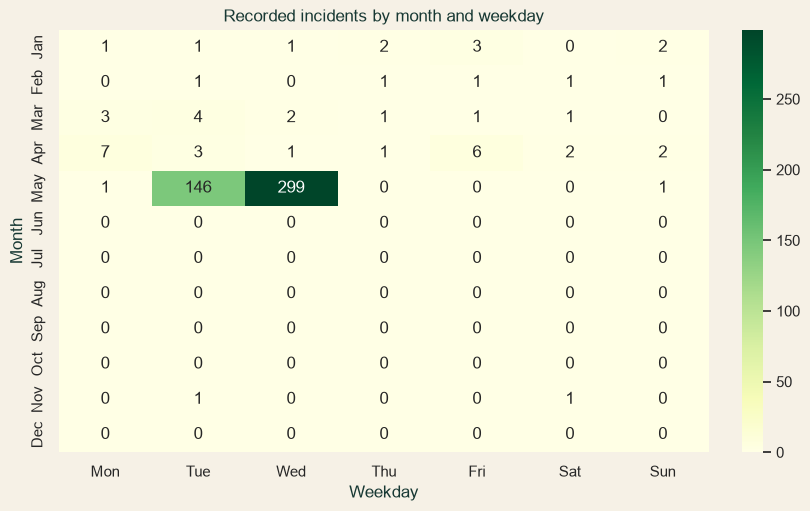

May has the most observations (447 records).


In [9]:
calendar_counts = pd.crosstab(incidents["month"], incidents["day_of_week"]).reindex(
    index=range(1, 13), columns=range(7), fill_value=0
)
month_names = list(calendar.month_abbr)[1:]
calendar_counts.index = month_names
calendar_counts.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
sns.heatmap(calendar_counts, cmap="YlGn", annot=True, fmt="d", ax=ax)
ax.set(title="Recorded incidents by month and weekday", xlabel="Weekday", ylabel="Month")
plt.show()

month_totals = calendar_counts.sum(axis=1)
print(f"{month_totals.idxmax()} has the most observations ({month_totals.max()} records).")

### 4. Community counts and population context

Keep all reference communities in the comparison, including areas with zero incidents. A population-adjusted figure is the sample count divided by the supplied population, multiplied by 10,000.

,community_code,community_name,population,incidents,per_10000
24,25,Austin,98882,34,3.44
22,23,Humboldt Park,55598,20,3.6
7,8,Near North Side,104712,20,1.91
67,68,Englewood,21411,16,7.47
29,30,South Lawndale,68798,16,2.33
42,43,South Shore,54345,16,2.94
31,32,Loop,42181,15,3.56
70,71,Auburn Gresham,45049,14,3.11
5,6,Lake View,101163,14,1.38
48,49,Roseland,36700,14,3.81


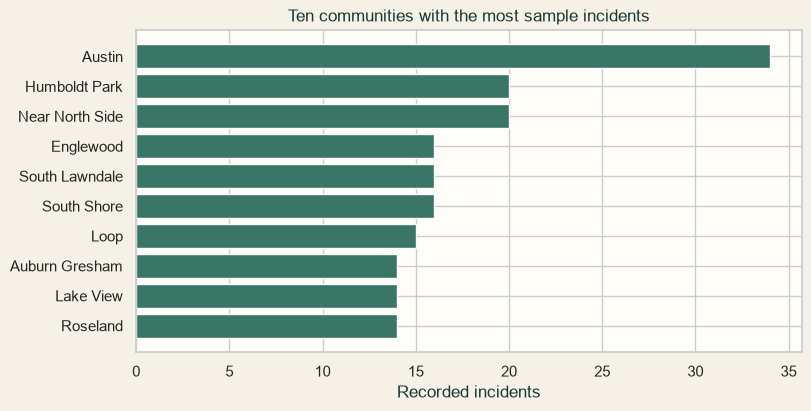

In [10]:
area_counts = incidents.groupby("community_code").size().rename("incidents")
community_stats = areas.merge(area_counts, on="community_code", how="left")
community_stats["incidents"] = community_stats["incidents"].fillna(0).astype(int)
meaningful_population = community_stats["population"].where(community_stats["population"] > 0)
community_stats["per_10000"] = 10_000 * community_stats["incidents"] / meaningful_population

top_areas = community_stats.sort_values(
    ["incidents", "community_name"], ascending=[False, True]
).head(10)
display(top_areas.round({"per_10000": 2}))

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.barh(top_areas["community_name"], top_areas["incidents"], color=green)
ax.invert_yaxis()
ax.set(title="Ten communities with the most sample incidents", xlabel="Recorded incidents")
plt.show()

Raw counts and population-adjusted counts answer different questions. Both describe the supplied sample, and the population values have no reference year in the source.

## Use Case 3 · Check statistical patterns

### 1. Community outliers

The interquartile range is `Q3 − Q1`. Counts outside the fences `Q1 − 1.5 × IQR` and `Q3 + 1.5 × IQR` are flagged for examination.

Mean = 6.47, Q1 = 2, Q3 = 9, IQR = 7
Fences: -8.5 to 19.5


,community_name,incidents
24,Austin,34
7,Near North Side,20
22,Humboldt Park,20


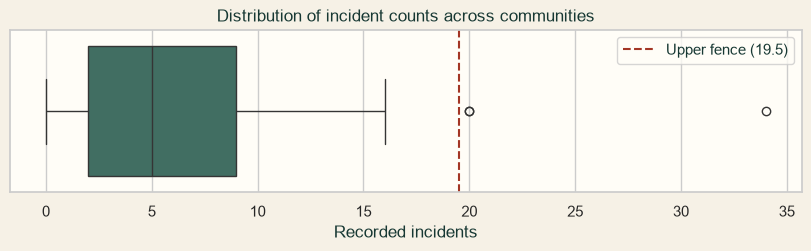

In [11]:
counts = community_stats["incidents"].to_numpy()
q1, q3 = np.percentile(counts, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = community_stats.loc[~community_stats["incidents"].between(lower, upper)]

print(f"Mean = {np.mean(counts):.2f}, Q1 = {q1:g}, Q3 = {q3:g}, IQR = {iqr:g}")
print(f"Fences: {lower:g} to {upper:g}")
display(outliers[["community_name", "incidents"]].sort_values("incidents", ascending=False))

fig, ax = plt.subplots(figsize=(8, 2.4), layout="constrained")
sns.boxplot(x=counts, color=green, ax=ax)
ax.axvline(upper, color=rust, linestyle="--", label=f"Upper fence ({upper:g})")
ax.set(title="Distribution of incident counts across communities", xlabel="Recorded incidents")
ax.legend()
plt.show()

### 2. Correlation and time precision

Pearson correlation describes a linear association. The month and weekday are calendar codes, and the arrest and domestic flags are binary. Interpret those associations in the context of the concentrated sample. Hourly analysis requires an explicit incident time.

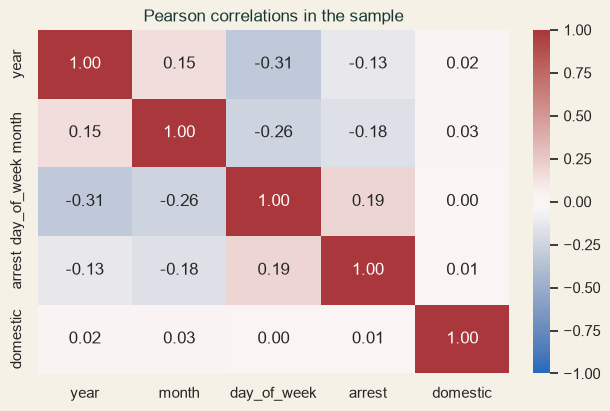

In [12]:
numeric = incidents[["year", "month", "day_of_week", "arrest", "domestic"]]
numeric = numeric.loc[:, numeric.nunique() > 1]
correlation = numeric.corr(method="pearson", min_periods=2)
if correlation.shape[0] >= 2:
    fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
    sns.heatmap(correlation, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax)
    ax.set_title("Pearson correlations in the sample")
    plt.show()
else:
    print("Too few varying fields for a correlation heatmap.")

In [13]:
timed = incidents.loc[incidents["has_time"] == 1]
print(f"Incidents with an explicit time: {len(timed)}")
if timed.empty:
    print("Hourly analysis is unavailable because the incident CSV contains dates only.")
else:
    hourly = timed.groupby("hour").size().reindex(range(24), fill_value=0)
    ax = hourly.plot(marker="o", color=green, figsize=(8, 3))
    ax.set(title="Incidents with known times by hour", xlabel="Hour", ylabel="Incidents")
    plt.show()

Incidents with an explicit time: 0
Hourly analysis is unavailable because the incident CSV contains dates only.


## Use Case 4 · Reconcile the analysis with SQL

Build a fresh database with the existing pipeline in a temporary directory. Query the two reporting views and check that the yearly summary table matches the yearly view. The temporary directory is removed after the cell finishes.

In [14]:
with TemporaryDirectory(prefix="chicago-analysis-") as folder:
    temporary = Path(folder)
    notebook_db = temporary / "analysis.db"
    imported = run_pipeline(db_path=notebook_db)
    engine = create_read_engine(notebook_db)
    try:
        with engine.connect() as connection:
            sql_yearly = pd.read_sql_query(
                text("SELECT * FROM vw_crime_yearly ORDER BY year"), connection
            )
            sql_top_five = pd.read_sql_query(text("""
                SELECT primary_type, crime_count, percentage
                FROM vw_crime_by_category
                ORDER BY crime_count DESC, primary_type
                LIMIT 5
            """), connection)
            stored_yearly = pd.read_sql_query(
                text("SELECT * FROM summary_yearly ORDER BY year"), connection
            )
    finally:
        engine.dispose()

assert imported["joined_records"] == len(incidents)
pd.testing.assert_frame_equal(sql_yearly, stored_yearly)
assert sql_yearly["crime_count"].tolist() == yearly["incidents"].tolist()
assert sql_yearly["arrest_count"].tolist() == yearly["arrests"].tolist()
assert sql_top_five["primary_type"].tolist() == categories.head(5)["primary_type"].tolist()
assert sql_top_five["crime_count"].tolist() == categories.head(5)["incidents"].tolist()
display(sql_yearly)
display(sql_top_five)
print("SQL and Pandas agree on yearly incident and arrest counts and on the top five categories.")

,year,crime_count,arrest_count,arrest_known_count,arrest_percentage
0,2012,2,2,2,100.00
1,2013,1,1,1,100.00
2,2014,1,0,1,0.00
3,2015,4,2,4,50.00
4,2016,490,119,490,24.29


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63


SQL and Pandas agree on yearly incident and arrest counts and on the top five categories.


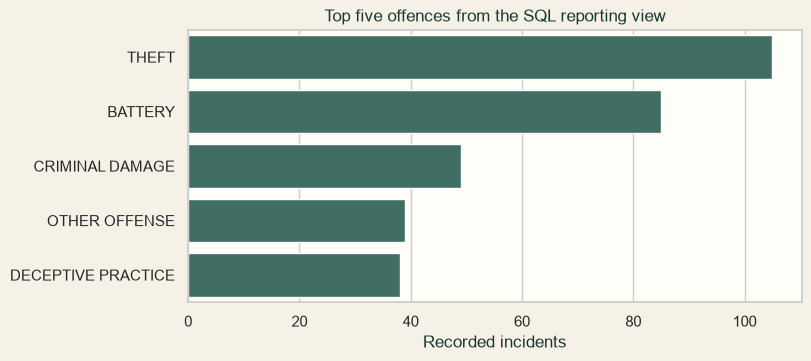

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
sns.barplot(data=sql_top_five, x="crime_count", y="primary_type", color=green, ax=ax)
ax.set(title="Top five offences from the SQL reporting view", xlabel="Recorded incidents", ylabel="")
plt.show()

## How this connects to the application

- **`use_case_1.py`** turns the six source files into validated incidents and database tables. The same cleaning functions are exercised in the notebook.
- **`analysis.py`** reads the database and turns common reporting operations into reusable functions.
- **`app.py`** calls those reporting functions for Flask pages and charts. The app reads the working database after a record is added, edited, or deleted.

For a short demonstration, show the two parser repairs, explain the uneven date coverage, and compare the top offences from Pandas and SQL. Those three outputs connect data quality, interpretation, and the application.